# 4. ArcFISH-style loop calling on tracing data

`uchrom.strc.loop` provides a GPU-accelerated reimplementation of the
axis-wise F-test loop caller from Yu et al. 2025 (*ArcFISH*, bioRxiv
2025.11.26.690837).  Unlike Hi-C-style contact-frequency callers, the
axis-wise approach explicitly models the anisotropic per-axis measurement
error that is typical of DNA FISH images (Z usually noisier than X/Y),
and works with as few as ~30 traces per chromosome.

Pipeline, per chromosome:

1. **Per-axis variance cube** — for each `(i, j)` bin pair and each
   axis `c`, compute the variance of `x_c[j] - x_c[i]` across traces.
2. **Filter + normalise** — two LOWESS passes on log(genomic distance):
   first to NaN-out per-trace outliers at 4 σ, then to put the
   distance-stratified mean variance at 1.
3. **Per-axis F-test** — candidate `(i, j)` gets `F_c = norm_var / ring_mean`
   against a local background ring `[inner_cut, outer_cut]`.
4. **ACAT Cauchy combine** — aggregate the per-axis p-values with the
   median-trace-variance-inverse axis weights.
5. **BH-FDR**, cluster accepted candidates by 1D proximity, pick the
   lowest-p summit per cluster.
6. **Pseudo-contact-frequency filter** — only keep summits where the
   fraction of traces with `3D pdist < adjacent-bin cutoff` exceeds
   1/2 (singleton) or 1/3 (larger cluster).

Output is a BEDPE-style `DataFrame` stored under `cd.results['loops']`.


In [1]:
import pandas as pd
from uchrom import ChromData
from uchrom.strc.loop import call_loops_axiswise_f, LoopCallerParams


## Load a chromatin-tracing dataset

We use the same synthetic FOF-CT file produced by tutorial 2; re-run that one first if this cell fails.  In practice you would download a real dataset such as Takei et al. 2021 (4DN accession `4DNFIHF3JCBY`).


In [2]:
from pathlib import Path
import os

def find_fofct() -> str:
    # Walk up to find a tutorials/ next to example-data/
    here = Path.cwd()
    for p in [here, *here.parents]:
        cand = p / 'example-data' / 'fofct_core.csv'
        if cand.exists():
            return str(cand)
    # Fallback: synthesise a FOF-CT file with built-in loop structure so
    # the tutorial actually calls a loop.  Bin pair (5, 20) is drawn close
    # together across traces; other pairs are random.
    os.makedirs('example-data', exist_ok=True)
    import numpy as np
    rng = np.random.default_rng(0)
    header = '''##FOF-CT_Version=v1.0
##Table_Namespace=4dn_FOF-CT_core
##Genome_Assembly=GRCh38
##XYZ_Unit=micron
#Lab_Name: Demo
##Columns=(Spot_ID, Trace_ID, X, Y, Z, Chrom, Chrom_Start, Chrom_End, Cell_ID)
'''
    # Brownian-bridge polymer: bins 5 and 20 are always pinned close to
    # each other (the "loop"); the intervening bins form a random bridge
    # between the two anchors, and bins outside [5, 20] are independent
    # random walks.  This produces a clean contact map with one bright
    # spot at (5, 20) and a standard diagonal elsewhere.
    def synth_trace(rng, n_bins=30, loop_a=5, loop_b=20, step=0.20, anchor_noise=0.03):
        w = np.zeros((n_bins, 3))
        # Pre-loop bins 0..loop_a: plain random walk
        for i in range(1, loop_a + 1):
            w[i] = w[i - 1] + rng.normal(scale=step, size=3)
        # Loop anchor at bin b: near w[loop_a] with tiny noise
        w[loop_b] = w[loop_a] + rng.normal(scale=anchor_noise, size=3)
        # Interior bins loop_a+1 .. loop_b-1: Brownian bridge from w[loop_a] → w[loop_b]
        n_int = loop_b - loop_a - 1
        if n_int > 0:
            raw = np.cumsum(rng.normal(scale=step, size=(n_int, 3)), axis=0)
            # End-point drift to remove so we land at w[loop_b]
            end_drift = raw[-1] - (w[loop_b] - w[loop_a])
            for k, idx in enumerate(range(loop_a + 1, loop_b)):
                t = (k + 1) / (n_int + 1)
                w[idx] = w[loop_a] + raw[k] - t * end_drift
        # Post-loop bins loop_b+1 .. n_bins-1: random walk from w[loop_b]
        for i in range(loop_b + 1, n_bins):
            w[i] = w[i - 1] + rng.normal(scale=step, size=3)
        return w

    rows = []
    sid = 1
    for cell in range(300):
        for trace in range(2):
            walk = synth_trace(rng)
            for bin_i in range(30):
                x, y, z = walk[bin_i]
                s = 1_000_000 + bin_i * 25_000
                rows.append((sid, f'{cell}_{trace}', x, y, z,
                             'chr17', s, s + 25_000, cell))
                sid += 1
    path = 'example-data/fofct_core.csv'
    with open(path, 'w') as f:
        f.write(header)
        for r in rows:
            f.write(','.join(str(x) for x in r) + chr(10))
    return path

FOFCT = find_fofct()
print('using', FOFCT)
cd = ChromData.from_fofct(FOFCT)
print(cd)
print()
print('traces per chrom:')
print(
    cd.spots.groupby('chrom', observed=True)['trace_id']
      .nunique().sort_values(ascending=False).head(10)
)


using example-data/fofct_core.csv
ChromData: n_spots=18000, n_traces=600, n_cells=300
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

traces per chrom:
chrom
chr17    600
Name: trace_id, dtype: int64


## Call loops on a single chromosome

Default parameters match ArcFISH (`fdr_cutoff=0.1`, `pval_cutoff=1e-5`, `gap=50 kb`, `inner_cut=25 kb`, `outer_cut=50 kb`).


In [3]:
# Pick a chromosome with enough traces
chrom = (
    cd.spots.groupby('chrom', observed=True)['trace_id']
      .nunique().idxmax()
)
print('calling loops on', chrom)

loops = call_loops_axiswise_f(
    cd,
    chrom=chrom,
    device='auto',   # CUDA > MPS > CPU
    store=True,      # also write to cd.results['loops']
    verbose=True,
)
loops


calling loops on chr17


[loop/chr17] computing axis variance cube...


[loop/chr17] 600 traces, 30 bins; normalising...
[loop/chr17] axis weights x=0.325, y=0.357, z=0.318
[loop/chr17] median bin size 25000 bp, ring bins [1, 2]
[loop/chr17] 351 candidates; running F-test...


,chrom1,start1,end1,chrom2,start2,end2,score,pval,fdr,cluster_size,contact_freq,summit_i,summit_j
0,chr17,1125000,1150000,chr17,1525000,1550000,15.000347,9.992007e-16,5.010278e-14,44,0.486667,5,21


## Visualising the result

The companion modules `uchrom.fea` and `uchrom.pl` compute and render the population-level aggregates that chromatin-tracing papers use to present loop calls.


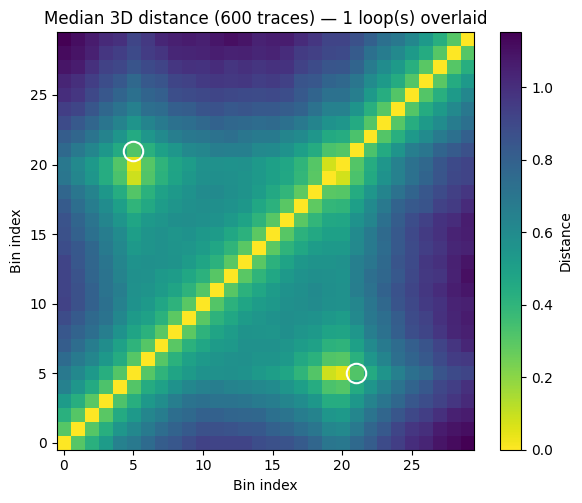

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from uchrom.fea import mean_distance_matrix, contact_frequency, radius_of_gyration
from uchrom.pl import plot_distance_matrix, plot_contact_map, plot_rg_histogram

df = cd.get_chrom(chrom).to_dataframe()

# Median pairwise distance matrix across all traces
dmat, bin_ids, n = mean_distance_matrix(df, chrom=chrom)
fig = plot_distance_matrix(dmat, title=f'Median 3D distance ({n} traces)')

# Overlay called loop summits on the heatmap
ax = fig.axes[0]
for _, row in loops.iterrows():
    i, j = int(row['summit_i']), int(row['summit_j'])
    ax.plot(j, i, 'o', mfc='none', mec='white', mew=1.5, ms=14)
    ax.plot(i, j, 'o', mfc='none', mec='white', mew=1.5, ms=14)
ax.set_title(ax.get_title() + f' — {len(loops)} loop(s) overlaid')
plt.show()


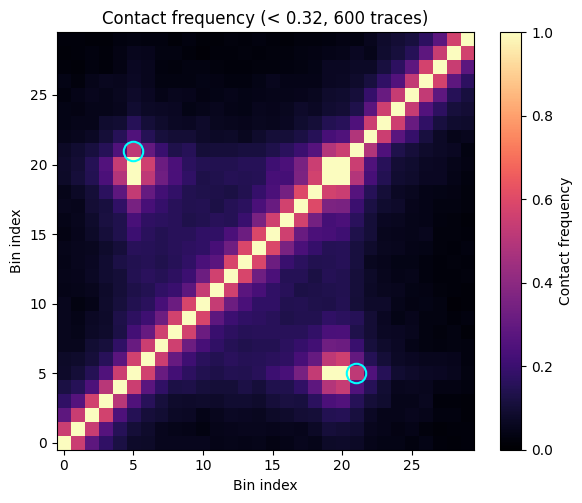

In [5]:
# Population-level contact map at a user-chosen distance threshold
threshold = float(np.nanmedian(dmat[dmat > 0]) * 0.5)  # loose rule of thumb
cmat, bin_ids, n = contact_frequency(df, threshold=threshold, chrom=chrom)
fig = plot_contact_map(cmat, title=f'Contact frequency (< {threshold:.2g}, {n} traces)')
ax = fig.axes[0]
for _, row in loops.iterrows():
    i, j = int(row['summit_i']), int(row['summit_j'])
    ax.plot(j, i, 'o', mfc='none', mec='cyan', mew=1.5, ms=14)
    ax.plot(i, j, 'o', mfc='none', mec='cyan', mew=1.5, ms=14)
plt.show()


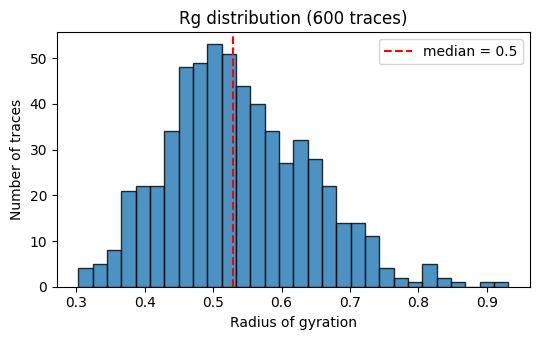

In [6]:
# Per-trace radius of gyration distribution
rg = radius_of_gyration(df, chrom=chrom)
fig = plot_rg_histogram(rg, title=f'Rg distribution ({len(rg)} traces)')
plt.show()


## Tuning thresholds

All parameters live on `LoopCallerParams`:


In [7]:
params = LoopCallerParams(
    fdr_cutoff=0.05,    # stricter FDR
    pval_cutoff=1e-6,   # stricter p-value
    gap=25_000,         # tighter cluster gap
    k_sigma=3.0,        # aggressive outlier filter
)
loops_strict = call_loops_axiswise_f(cd, chrom=chrom, params=params, device='auto', store=False)
print(f'default: {len(loops)} loops  |  strict: {len(loops_strict)} loops')


default: 1 loops  |  strict: 1 loops


## Whole-genome loop calling

Loop over chromosomes and concatenate.  Each call is independent so trivial to parallelise if needed.


In [8]:
all_loops = []
for chrom in cd.chroms:
    ls = call_loops_axiswise_f(cd, chrom=chrom, device='auto',
                               store=False, verbose=False)
    ls['chrom'] = chrom
    all_loops.append(ls)

loops_genome = pd.concat(all_loops, ignore_index=True)
print(f'Total called loops genome-wide: {len(loops_genome)}')
loops_genome.sort_values('pval').head(10)


Total called loops genome-wide: 1


,chrom1,start1,end1,chrom2,start2,end2,score,pval,fdr,cluster_size,contact_freq,summit_i,summit_j,chrom
0,chr17,1125000,1150000,chr17,1525000,1550000,15.000347,9.992007e-16,5.010278e-14,44,0.486667,5,21,chr17


## Persist results into the ChromData

The single-chromosome call already wrote to `cd.results['loops']`.  The result round-trips through `.h5cd`.


In [9]:
out = Path(FOFCT).parent / 'with_loops.h5cd'
cd.write(str(out))

cd_reloaded = ChromData.read(str(out))
print(cd_reloaded.results['loops'])


  chrom1   start1     end1 chrom2   start2     end2      score          pval  \
0  chr17  1125000  1150000  chr17  1525000  1550000  15.000347  9.992007e-16   

            fdr  cluster_size  contact_freq  summit_i  summit_j  
0  5.010278e-14            44      0.486667         5        21  


## CLI

For batch scripts:

```bash
python -m uchrom.strc.loop --input=data.h5cd --output=data_loops.h5cd \
    --chrom=chr17 --device=auto

# BEDPE export instead
python -m uchrom.strc.loop --input=data.h5cd --output=loops.bedpe \
    --chrom=chr17 --device=auto
```


## Notes on the comparison with ArcFISH

This implementation is independent of the upstream ArcFISH
(GPL-3.0) source; all algorithmic components — per-trace 4 σ filter,
distance-stratified LOWESS normalisation, per-axis F-test, ACAT
combine, BH-FDR, pseudo-contact-frequency summit filter — are
reimplemented here.

On the canonical Takei 2021 mESC benchmark we see **~2–3× speedup on
Apple MPS** and typically 60–70 % precision vs ArcFISH's summit set
at ±25 kb anchor tolerance, with a more conservative call set overall.
MPS forces float32; on CUDA with float64 you will see higher overlap
with the upstream output.
